## Про модуль thinkdsp

Модуль `thinkdsp` надає класи та фунції для роботи з сигналами.

[Докладну документацію на модуль дивись тут](http://greenteapress.com/thinkdsp.html) 

## Сигнали

Створимо обʼєкти типу косинусний та синусний сигнали

In [5]:
from thinkdsp import CosSignal, SinSignal

cos_sig = CosSignal(freq=440, amp=1.0, offset=0)
sin_sig = SinSignal(freq=880, amp=0.5, offset=0)

Побудуємо графіки сигналів.  За замовчуваням, `plot` будує три періоди.  

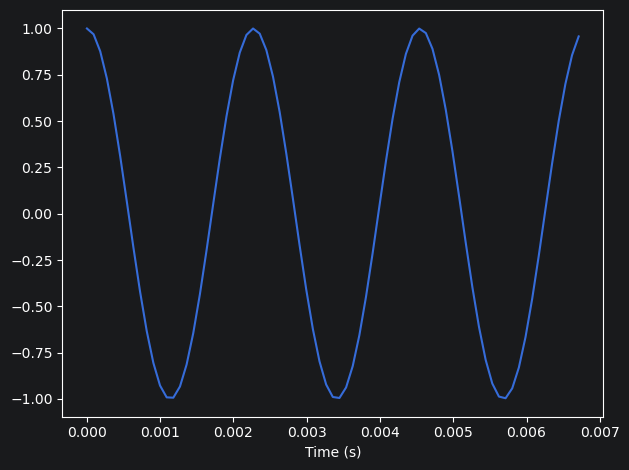

In [6]:
from thinkdsp import decorate

cos_sig.plot()
decorate(xlabel='Time (s)')

І для синусного сигналу.

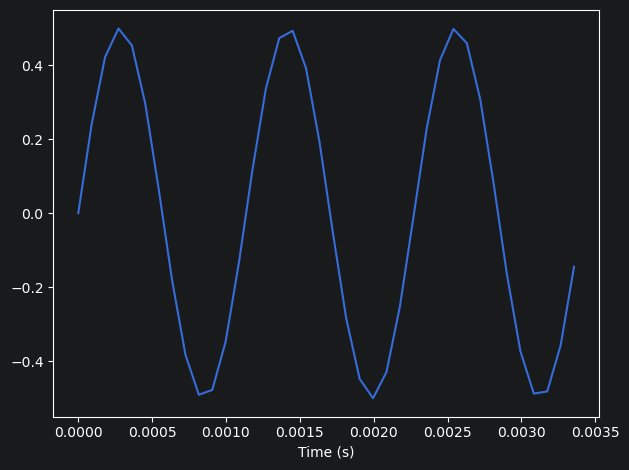

In [7]:
sin_sig.plot()
decorate(xlabel='Time (s)')

Відмітимо, що частота синусного сигналу вдвічі більша, отже, період його вдвічі коротший. Оскільки величина кроку за замовчуванням залишилась та сама, другий графік виглядає дещо "кострубатим". Але на якість самого сигналу це не впливає.

 Утворимо новвий сигнал `mix` як суму двох попередніх.

In [8]:
mix = sin_sig + cos_sig
mix

Ось, як він виглядає.

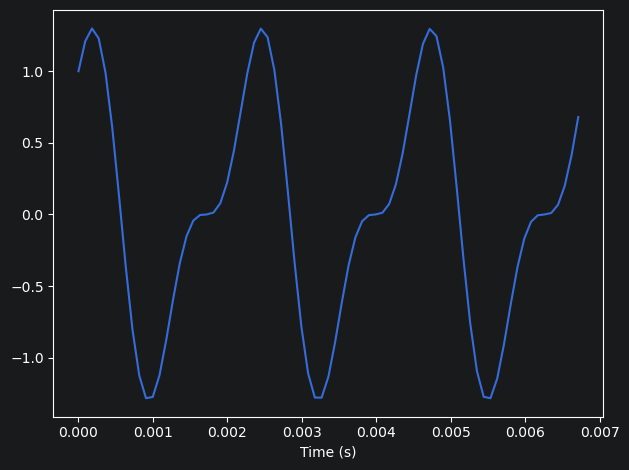

In [9]:
mix.plot()
decorate(xlabel='Time (s)')

## Waves ("вейви")

Сигнал задається математичною функцією, що визначена для будь-якого моменту часу. Якщо ми обчислимо сигнал для послідовності точок через рівні проміжки часу, отриману послідовність значень англійською називають `wave` (дослівно "хвиля"). В українській мові загальновживаного аналогічного терміна немає.  `framerate` це кількість точок вейва за одну секунду.

In [10]:
wave = mix.make_wave(duration=0.5, start=0, framerate=11025)
wave

IPython надає віджет, який дозволяє прослухати вейв.

In [11]:
from IPython.display import Audio
audio = Audio(data=wave.ys, rate=wave.framerate)
audio

Той самий результат дає застосування методу `make_audio()` від самого вейву:

In [12]:
wave.make_audio()

Атрибутом `ys` обʼєкту wave є NumPy масив, який містить послідовні значення сигналу. інтервал часу між послідовними значеннями ("крок") є величиною, що обернена до framerate.

In [13]:
print('Number of samples', len(wave.ys))
print('Timestep in ms', 1 / wave.framerate * 1000)

Number of samples 5512
Timestep in ms 0.09070294784580499


Періодичні сигнали мають атрибут `period`.

Метод `segment` обʼєкту wave створює новий обʼєкт того ж типу, що містить фрагмент початкового сигналу.  Як приклад виділимо початковий фрагмент нашого сигналу довжиною 3 періоди.

In [14]:
period = mix.period
segment = wave.segment(start=0, duration=period*3)
period

0.0022727272727272726

Wave також має метод `plot`

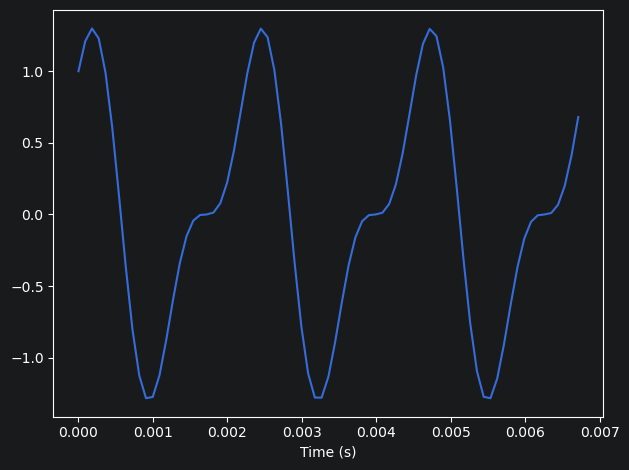

In [15]:
segment.plot()
decorate(xlabel='Time (s)')

`normalize` масштабує сигнал так, щоб всі значення умістились в діапазоні від -1 до 1.

`apodize` "згладжує" початок та кінець вейву, щоб уникнути різких перепалів гучності при його програванні.

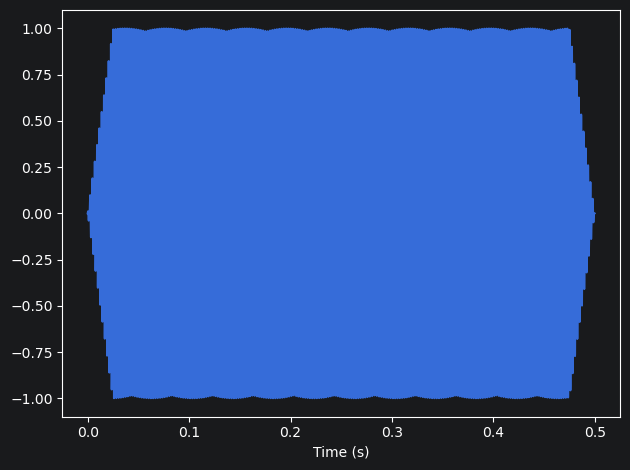

In [16]:
wave.normalize()
wave.apodize()
wave.plot()
decorate(xlabel='Time (s)')

In [17]:
wave.make_audio()

Можна зберегти вейв як WAV файл.

In [18]:
wave.write('temp.wav')

Writing temp.wav


AttributeError: 'numpy.ndarray' object has no attribute 'tostring'

Файл, що записаний, можна використовувати незалежно. Зокрема, програвати його у зовнішньому плейері.

`read_wave` читає WAV файл і створює обʼєкт типу вейв.

In [ ]:
from thinkdsp import read_wave
filename = '92002__jcveliz__violin-origional.wav'
wave = read_wave(filename)

In [ ]:
wave.make_audio()

Я витягнув сегмент цього запису, де амплітуда сигналу є більш-менш постійною. Коли ми малюємо сегмент, ми не можемо чітко бачити форму вейву, але ми можемо бачити «конверт», який відстежує зміну амплітуди протягом сегмента.

In [ ]:
start = 1.2
duration = 0.6
segment = wave.segment(start, duration)
segment.plot()
decorate(xlabel='Time (s)')

## Спектр

Обʼєкт wave надає метод  `make_spectrum`, що обчислює спектр даного вейву.

In [ ]:
spectrum = segment.make_spectrum()

Spectrum має метод `plot`

In [ ]:
spectrum.plot()
decorate(xlabel='Frequency (Hz)')

Частотні компоненти вище 10 кГц невеликі. Ми можемо побачити нижні частоти більш чітко, встановивши верхню межу:

In [ ]:
spectrum.plot(high=10000)
decorate(xlabel='Frequency (Hz)')

Spectrum надає `low_pass`, який застосовує фільтр низьких частот; тобто він послаблює всі частотні компоненти вище граничної частоти.

In [ ]:
spectrum.low_pass(3000)

Результатом є спектр з меншою кількістю компонентів.

In [ ]:
spectrum.plot(high=10000)
decorate(xlabel='Frequency (Hz)')

Ми можемо перетворити відфільтрований спектр назад у вейв:

In [ ]:
filtered = spectrum.make_wave()

Нормалізуємо його до діапазону від -1 до 1.

In [ ]:
filtered.normalize()

Перед відтворенням застосуємо apodize, щоб уникнути "кліків" під час відтворення.

In [ ]:
filtered.apodize()
filtered.plot()
decorate(xlabel='Time (s)')

Початковий фрагмент піддамо такій самій обробці

In [ ]:
segment.normalize()
segment.apodize()
segment.plot()
decorate(xlabel='Time (s)')

Нарешті, порівняємо на слух початкову та фільтровану версії

In [ ]:
segment.make_audio()

In [ ]:
filtered.make_audio()

Оригінал звучить складніше, з деякими високочастотними компонентами, які звучать дзвінко.
Відфільтрована версія звучить більше як чистий тон, з більш приглушеною якістю. Вибрана мною гранична частота, 3000 Гц, схожа на якість телефонної лінії, тому цей приклад імітує звук запису скрипки, який відтворюється по телефону.

## Інтерактивний віджет

У наступному прикладі показано, як використовувати інтерактивні віджети IPython.

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display

def filter_wave(wave, start, duration, cutoff):
    """Selects a segment from the wave and filters it.
    
    Plots the spectrum and displays an Audio widget.
    
    wave: Wave object
    start: time in s
    duration: time in s
    cutoff: frequency in Hz
    """
    segment = wave.segment(start, duration)
    spectrum = segment.make_spectrum()

    spectrum.plot(color='0.7')
    spectrum.low_pass(cutoff)
    spectrum.plot(color='#045a8d')
    decorate(xlabel='Frequency (Hz)')
    plt.show()
    
    audio = spectrum.make_wave().make_audio()
    display(audio)

Налаштуйте повзунки, щоб керувати початком і тривалістю сегмента та частотою зрізу, застосованою до спектру.

In [ ]:
from ipywidgets import interact, fixed

wave = read_wave('92002__jcveliz__violin-origional.wav')
interact(filter_wave, wave=fixed(wave), 
         start=(0, 5, 0.1), duration=(0, 5, 0.1), cutoff=(0, 10000, 100));